In [2]:
# SVM implementation
import cvxpy as cvx
import numpy as np

#### CONSTANTS
FEATURE_SIZE = 1000

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

KeyboardInterrupt: ignored

In [3]:
class SVM:
  def __init__(self, feature_size):
    self.data = data
    self.feature_size = feature_size
    self.w = None
    self.b = None

  def fit(self, X, label, C=10):
    self.w = cvx.Variable(FEATURE_SIZE)
    self.b = cvx.Variable(1)
    slack_vars = cvx.Variable(len(label))

    objective = cvx.Minimize((cvx.square(cvx.norm(self.w))/2) + (C * cvx.norm(slack_vars, 1)))
    print(self.w.shape)
    
    constraints = [slack_vars >= 0]
    
    for i in range(len(label)):
      constraints.append(label[i]*(X[i,:] @ self.w + self.b) + slack_vars[i] - 1 >= 0)
    
    optim_prob = cvx.Problem(objective, constraints)
    sol = optim_prob.solve(solver='CVXOPT', verbose=True)


    if optim_prob.status not in ["infeasible", "unbounded"]:
      print("The optimization for SVM was successfully solved.")
    else:
      print("Unable to solve the optimization problem")

  def predict(self, x):
    return self.w.T @ x + self.b

In [4]:
# imports
import numpy as np

data = {}
#data['test']  = np.load('drive/MyDrive/dataverse_files/Dataset5_raw_test.npz')
data['train'] = dict(np.load('dataverse_files/Dataset5_raw_train.npz'))
data['val']   = dict(np.load('dataverse_files/Dataset5_raw_val.npz'))

In [6]:
#feature extraction from the image
## importing the necessary modules for feature extraction 
import torch
import torch.nn as nn
from torchvision import transforms, datasets
from torch.utils.data import Dataset, DataLoader
import pickle
# normalize image data
# N x 224 x 224 x3 
# take avg of N images 

mean = data['train']['image'].mean(axis=(0,1,2), keepdims=True)
devia = data['train']['image'].std(axis=(0,1,2), keepdims=True)
data['train']['image'] = (data['train']['image'] - mean) / devia
data['val']['image'] = (data['val']['image'] - mean) / devia

In [7]:
class CustomDataset(Dataset):
    def __init__(self, data, labels, transform):
        self.transform = transform
        self.data = data
        self.labels = labels
    
    def __len__(self):
        return self.labels.size

    def __getitem__(self, idx):
        temp = int(self.labels[idx])
            
        return self.transform(self.data[idx]).float(), temp

In [14]:
transform = transforms.Compose([transforms.ToTensor()])
print(data['train']['image'].transpose(0, 3, 1, 2).shape)
trainset = CustomDataset(data['train']['image'], data['train']['image_label'], transform)
train_loader = DataLoader(trainset, 64, shuffle=True, drop_last=True)

(19610, 3, 224, 224)


In [8]:
class Model(nn.Module):
  def __init__(self, cnn):
    super().__init__()
    self.cnn = cnn

    self.fcn = nn.Sequential(
            nn.Linear(1000, 5),
            nn.Softmax(),
        )

  def forward(self, inp):
    return self.cnn(inp)

  def save_FExt(self):
    torch.save(self.cnn.state_dict(), 'vgg16_xray')

  def load_FExt(self):
    model.load_state_dict(torch.load("feweights/modelres18_57.pth"))

In [11]:
import torchvision

resnet18 = torchvision.models.resnet18() 
model = Model(resnet18)
model.load_FExt()
model.eval()

Model(
  (cnn): ResNet(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_s

In [12]:
y_pred = []
y_train = []
for x, y in train_loader:
    y_pred = y_pred + model(x).detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))

NameError: ignored

In [15]:
print(data['val']['image'].transpose(0, 3, 1, 2).shape)

valset = CustomDataset(data['val']['image'], data['val']['image_label'], transform)
val_loader = DataLoader(valset, 1, shuffle=True)

(6534, 3, 224, 224)


In [16]:
y_pred_val = []
y_val = []
for x, y in val_loader:
    y_pred_val.append(model(x).detach().numpy())
    y_val.append(y.detach().numpy()[0])
    
print(len(y_pred_val))
print(y_pred_val[1].shape)
print(len(y_val))

y_net = np.reshape(np.array(y_pred),(-1,1000))
y_net_val = np.array(y_pred_val).reshape(-1,1000)

6534
(1, 1000)
6534


In [ ]:
# we will create 4 different SVMs for 5 classes
# we will create 4 copies of the labels
'''
COVID-19 :  4,189 : 0.          -  0 
Lung-Opacity : 6,012 : 1.       -  1 
Normal : 10,192 : 2             -  2
Viral Pneumonia : 7,397 : 3.    -  3
Tuberculosis : 4,897 : 4        -  4


10 svms

01.  -  0 vs 1
02   -  0 vs 2
03 
04
12
13
14
23
24
34
'''
import pickle

labels = {}
svms = {}
items = {}

for i in range(5):
  for k in range(i, 5):
    labels[str(i)+str(k)] = []
    items[str(i)+str(k)]  = []
    
labels['0'], labels['1'], labels['2'], labels['3'] =  [], [], [], []
for i in range(len(y_train)):
  y = y_train[i]

  if y == 0:
    items["01"].append(y_net[i])
    items["02"].append(y_net[i])
    items["03"].append(y_net[i])
    items["04"].append(y_net[i])
    labels["01"].append(1)
    labels["02"].append(1)
    labels["03"].append(1)
    labels["04"].append(1)

  if y == 1:
    items["01"].append(y_net[i])
    items["12"].append(y_net[i])
    items["13"].append(y_net[i])
    items["14"].append(y_net[i])
    labels["01"].append(-1)
    labels["12"].append(1)
    labels["13"].append(1)
    labels["14"].append(1)

  if y == 2:
    items["02"].append(y_net[i])
    items["12"].append(y_net[i])
    items["23"].append(y_net[i])
    items["24"].append(y_net[i])
    labels["02"].append(-1)
    labels["12"].append(-1)
    labels["23"].append(1)
    labels["24"].append(1)

  if y == 3:
    items["03"].append(y_net[i])
    items["13"].append(y_net[i])
    items["23"].append(y_net[i])
    items["34"].append(y_net[i])
    labels["03"].append(-1)
    labels["13"].append(-1)
    labels["23"].append(-1)
    labels["34"].append(1)


  if y == 4:
    items["04"].append(y_net[i])
    items["14"].append(y_net[i])
    items["24"].append(y_net[i])
    items["34"].append(y_net[i])
    labels["04"].append(-1)
    labels["14"].append(-1)
    labels["24"].append(-1)
    labels["34"].append(-1)


print(np.array(items["01"]).shape)
print(np.array(labels["01"]).shape)
for i in range(5):
  for k in range(i+1, 5):
    svms[str(i)+str(k)] = SVM(1000)
    
    print("Solving SVM label:", str(i)+str(k))

    if len(items[str(i)+str(k)]) > 8000:
      items[str(i)+str(k)] = items[str(i)+str(k)][:8000]
      labels[str(i)+str(k)] = labels[str(i)+str(k)][:8000]
    svms[str(i)+str(k)].fit(np.array(items[str(i)+str(k)]), np.array(labels[str(i)+str(k)]))

    with open(f'adam_2layer_weights{str(i)+str(k)}.pkl', 'wb') as fp:
      pickle.dump(svms[str(i)+str(k)].w, fp)
      print('weights saved successfully to file', )

    with open(f'adam_2layer_bias{str(i)+str(k)}.pkl', 'wb') as fp:
      pickle.dump(svms[str(i)+str(k)].b, fp)
      print('bias saved successfully to file')

(6108, 1000)
(6108,)
Solving SVM label: 01
(1000,)
                                     CVXPY                                     
                                     v1.3.1                                    
(CVXPY) May 17 11:06:39 AM: Your problem has 7109 variables, 6109 constraints, and 0 parameters.
(CVXPY) May 17 11:06:40 AM: It is compliant with the following grammars: DCP, DQCP
(CVXPY) May 17 11:06:40 AM: (If you need to solve this problem multiple times, but with different data, consider using parameters.)
(CVXPY) May 17 11:06:40 AM: CVXPY will first compile your problem; then, it will invoke a numerical solver to obtain a solution.
-------------------------------------------------------------------------------
                                  Compilation                                  
-------------------------------------------------------------------------------
(CVXPY) May 17 11:06:41 AM: Compiling problem (target solver=CVXOPT).
(CVXPY) May 17 11:06:41 AM: Reduction 

In [17]:
svms = {}
for i in range(5):
  for k in range(i+1, 5):
    svms[str(i)+str(k)] = SVM(1000)
    with open(f'drive/MyDrive/svms1/adam_2layer_weights{str(i)+str(k)}.pkl', 'rb') as fp:
      svms[str(i)+str(k)].w = pickle.load(fp)
      print('dictionary loaded successfully')

    with open(f'drive/MyDrive/svms1/adam_2layer_bias{str(i)+str(k)}.pkl', 'rb') as fp:
      svms[str(i)+str(k)].b = pickle.load(fp)
      print('dictionary loaded successfully')

dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully
dictionary loaded successfully


In [20]:
correct = 0
conf_matrix = np.zeros((5, 5))

for j in range(y_net_val.shape[0]):
  cur_counter = {}
  
  for i in range(5):
    cur_counter[str(i)] = 0

  for i in range(5):
    for k in range(i+1, 5):
      #print(y_net_val[i].shape)
      #print(svms[str(i)+str(k)].w.value.shape)
      prediction = y_net_val[j] @ np.array(svms[str(i)+str(k)].w.value) + np.array(svms[str(i)+str(k)].b.value)  
      #print(prediction)
      if prediction >= 0:
        cur_counter[str(i)] += 1
      else:
        cur_counter[str(k)] += 1
  
  maxind = 0
  for i in range(5):
    if cur_counter[str(i)] > cur_counter[str(maxind)]:
      maxind = i

  print(maxind)
  if maxind == y_val[j]:
    correct += 1

  conf_matrix[maxind, y_val[j]] += 1 

print((correct/y_net_val.shape[0])*100)
print(conf_matrix)

Streaming output truncated to the last 5000 lines.
0
3
3
2
3
3
2
2
3
0
1
2
2
2
3
2
3
4
4
3
1
0
1
4
3
1
1
1
2
2
0
2
1
2
4
3
3
3
1
4
3
3
2
1
0
0
3
1
4
2
2
3
2
1
0
2
4
2
3
4
2
1
0
4
3
1
4
3
4
2
2
4
2
1
2
4
2
2
2
1
1
2
3
2
4
3
2
3
3
4
2
1
0
2
0
3
2
3
2
2
4
2
1
0
3
2
2
2
2
2
3
2
4
2
0
2
4
1
2
2
0
4
0
3
1
4
3
1
1
4
0
2
1
1
0
3
3
2
1
3
4
1
4
3
2
3
1
1
1
2
1
3
0
4
4
1
3
2
4
3
2
2
3
1
0
1
2
1
0
3
0
3
4
3
1
3
1
2
4
1
2
2
1
1
3
3
1
2
4
2
2
4
3
2
1
2
1
1
1
4
2
2
3
0
3
2
4
3
2
3
3
2
1
3
1
3
3
3
2
2
1
4
4
3
1
2
2
1
3
2
2
2
2
0
2
2
2
3
3
2
1
4
2
3
1
2
2
2
2
3
2
1
4
2
4
4
1
3
0
2
3
1
3
2
1
0
1
4
0
0
1
4
2
3
3
0
3
4
3
3
1
2
1
2
0
1
2
2
1
1
3
1
3
2
2
2
1
2
0
2
3
1
4
2
3
2
3
1
4
3
0
0
4
2
1
4
4
4
4
2
2
3
2
2
3
2
2
2
3
1
1
2
1
2
4
0
3
1
3
2
0
2
2
2
4
2
0
2
1
3
3
2
2
3
0
0
2
1
3
2
4
0
0
3
0
3
2
2
4
3
4
0
3
3
1
0
4
0
1
2
2
2
0
0
0
3
3
0
1
2
2
2
3
1
4
4
4
3
4
1
4
4
3
4
4
2
4
2
2
2
1
4
0
1
2
2
1
0
2
2
2
2
4
3
3
1
3
2
2
4
2
4
2
4
2
2
0
1
4
0
0
4
3
2
2
2
4
2
2
3
1
2
2
3
0
3
3
2
4
4
0
3
2
1
3
2
2
3
4
4
4
3
4
2
3

<Axes: >

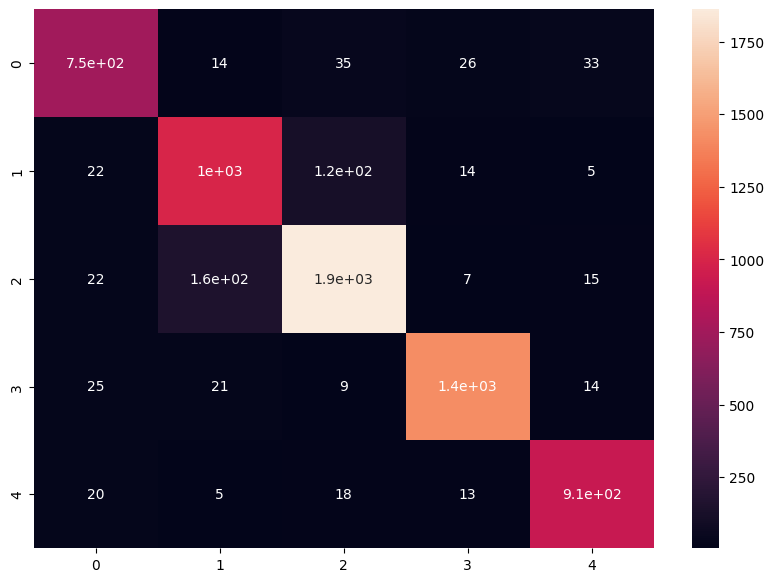

In [21]:
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize = (10,7))
sn.heatmap(conf_matrix, annot=True)

In [ ]:
data = {}
data['test']  = dict(np.load('dataverse_files/Dataset5_raw_test.npz'))
data['test']['image'] = (data['test']['image'] - mean) / devia
conf_matrix = np.zeros(shape=(5, 5))
transform = transforms.Compose([transforms.ToTensor()])
print(data['test']['image'].transpose(0, 3, 1, 2).shape)
testset = CustomDataset(data['test']['image'], data['test']['image_label'], transform)
test_loader = DataLoader(testset, 1, shuffle=True)


y_pred = []
y_train = []
for x, y in test_loader:
    y_pred = y_pred + model(x).detach().numpy().tolist()
    y_train = y_train + y.detach().numpy().tolist()
    
print(len(y_pred))
print(len(y_train))


y_net = np.reshape(np.array(y_pred),(-1,1000))

correct = 0
conf_matrix = np.zeros((5, 5))

for j in range(y_net_val.shape[0]):
  cur_counter = {}
  
  for i in range(5):
    cur_counter[str(i)] = 0

  for i in range(5):
    for k in range(i+1, 5):
      #print(y_net_val[i].shape)
      #print(svms[str(i)+str(k)].w.value.shape)
      prediction = y_net[j] @ np.array(svms[str(i)+str(k)].w.value) + np.array(svms[str(i)+str(k)].b.value)  
      #print(prediction)
      if prediction >= 0:
        cur_counter[str(i)] += 1
      else:
        cur_counter[str(k)] += 1
  
  maxind = 0
  for i in range(5):
    if cur_counter[str(i)] > cur_counter[str(maxind)]:
      maxind = i

  print(maxind)
  if maxind == y_train[j]:
    correct += 1

  conf_matrix[maxind, y_val[j]] += 1 

print((correct/y_net_val.shape[0])*100)
print(conf_matrix)

(6540, 3, 224, 224)
